# Uncertainty-Aware AI Models: Gaussian Processes and Deep Ensembles

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L13/L13_uncertainty_aware_models.ipynb)
### MECH 559 - Systems Optimization - L13
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Uncertainty-aware AI models in MDO* section of the lecture. An MDO
evaluation can cost hours (one converged MDA), so we want a model that replaces some of them.
A model that only returns a number $\hat y(\mathbf{x})$ cannot tell us when it is guessing. Here we
build two models that return a **distribution**
$\hat y(\mathbf{x}) \sim \mathcal{N}\big(\hat\mu(\mathbf{x}), \hat\sigma^2(\mathbf{x})\big)$:

- a **Gaussian process** (Kriging, Lecture 4), whose variance comes with the fit;
- a **deep ensemble** of $M$ small neural networks with two output heads, whose variance splits into
  an **aleatoric** part (noise in the data) and an **epistemic** part (lack of data).

We then check whether the predicted uncertainty can be trusted, which is what the next notebooks
need before they let a model skip a simulation.

## Learning objectives

1. Fit a GP and read its predictive standard deviation: small near the data, large away from it.
2. Implement a deep ensemble with dual output heads, trained with the heteroscedastic negative
   log-likelihood (NLL), and compute the mixture mean and variance from the slides.
3. Separate aleatoric and epistemic variance, and show which one shrinks when data is added.
4. Explain the role of the $\log\hat\sigma^2$ term in the NLL by removing it.
5. Check **calibration**: does a $\pm 2\hat\sigma$ band contain about 95% of new observations?

In [1]:
# %pip install torch scikit-learn

In [2]:
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

warnings.filterwarnings("ignore")
torch.set_num_threads(1)
plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"true": "#264653", "data": "black", "band": "#EDAE49", "mean": "#D1495B", "gp": "#1D5FA8",
          "aleatoric": "#2A9D8F", "epistemic": "#E76F51"}
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
rng = np.random.default_rng(559)
print(f"PyTorch {version('torch')}, scikit-learn {version('scikit-learn')}, NumPy {version('numpy')}")

PyTorch 2.15.0, scikit-learn 1.9.1, NumPy 2.5.5


---
## 1. A stand-in for an expensive MDA output

We use the 1-D Forrester function as the "true" response $y(x)$ of an MDA, on $x \in [0, 1]$. A real MDA
output is also slightly **noisy**: the MDA is converged to a tolerance, the CFD mesh changes with the
design, and so on. We model this numerical noise with a standard deviation that grows with $x$:

$$
y_{\text{obs}}(x) = y(x) + \sigma_{\text{noise}}(x)\,\epsilon, \qquad
\sigma_{\text{noise}}(x) = 0.2 + 1.5\,x, \qquad \epsilon \sim \mathcal{N}(0, 1).
$$

The training set leaves a **gap** in $[0.55, 0.75]$: no design was ever simulated there.

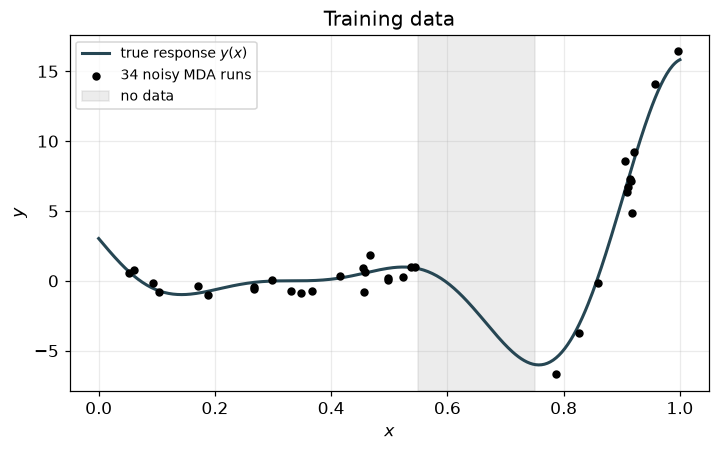

In [3]:
def y_true(x):
    return (6 * x - 2) ** 2 * np.sin(12 * x - 4)


def noise_std(x):
    return 0.2 + 1.5 * x


def observe(x, rng):
    return y_true(x) + noise_std(x) * rng.standard_normal(np.shape(x))


GAP = (0.55, 0.75)
X_train = np.sort(np.concatenate([rng.uniform(0.0, GAP[0], 22), rng.uniform(GAP[1], 1.0, 12)]))
y_train = observe(X_train, rng)
x_plot = np.linspace(0, 1, 400)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(x_plot, y_true(x_plot), color=COLORS["true"], lw=2, label="true response $y(x)$")
ax.scatter(X_train, y_train, color=COLORS["data"], s=20, zorder=5, label=f"{len(X_train)} noisy MDA runs")
ax.axvspan(*GAP, color="gray", alpha=0.15, label="no data")
ax.set(xlabel="$x$", ylabel="$y$", title="Training data")
ax.legend(fontsize=9); plt.show()

---
## 2. Gaussian process: uncertainty for free

A GP with a Matérn 5/2 kernel plus a white-noise kernel. The fitted kernel hyperparameters (length scale,
noise level) maximize the marginal likelihood. The prediction at a new $x_*$ is

$$
\hat\mu(x_*) = \mathbf{k}_*^{\top}\mathbf{K}^{-1}\mathbf{y}, \qquad
\hat\sigma^2(x_*) = k_{**} - \mathbf{k}_*^{\top}\mathbf{K}^{-1}\mathbf{k}_* .
$$

> **Checkpoint 1.** Before running: where will the GP band be widest? *Answer:* in the gap and beyond the
> last data point, where $\mathbf{k}_*$ is small and the second term cannot cancel $k_{**}$.

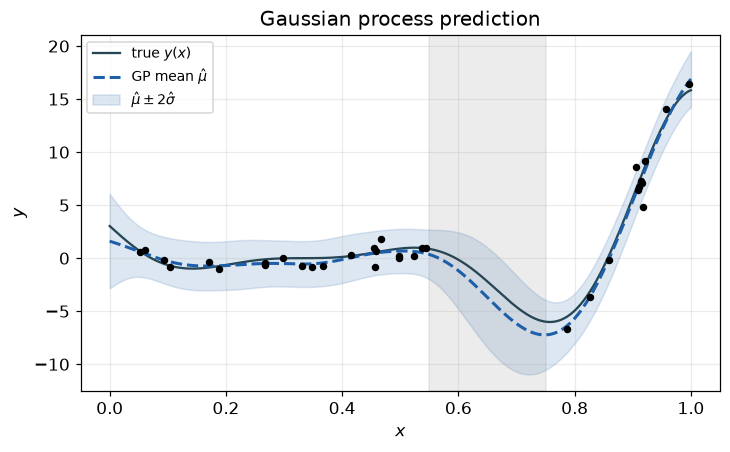

fitted kernel: 2.14**2 * Matern(length_scale=0.258, nu=2.5) + WhiteKernel(noise_level=0.0413)
mean GP std in the gap: 1.98   on [0.1, 0.5]: 1.10


In [4]:
kernel = ConstantKernel(10.0) * Matern(length_scale=0.2, nu=2.5) + WhiteKernel(1.0)
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=0)
gp.fit(X_train[:, None], y_train)
mu_gp, sd_gp = gp.predict(x_plot[:, None], return_std=True)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(x_plot, y_true(x_plot), color=COLORS["true"], lw=1.5, label="true $y(x)$")
ax.plot(x_plot, mu_gp, color=COLORS["gp"], lw=2, ls="--", label=r"GP mean $\hat\mu$")
ax.fill_between(x_plot, mu_gp - 2 * sd_gp, mu_gp + 2 * sd_gp, color=COLORS["gp"], alpha=0.15,
                label=r"$\hat\mu \pm 2\hat\sigma$")
ax.scatter(X_train, y_train, color=COLORS["data"], s=15, zorder=5)
ax.axvspan(*GAP, color="gray", alpha=0.15)
ax.set(xlabel="$x$", ylabel="$y$", title="Gaussian process prediction")
ax.legend(fontsize=9); plt.show()
print("fitted kernel:", gp.kernel_)
in_gap = (x_plot > GAP[0]) & (x_plot < GAP[1])
print(f"mean GP std in the gap: {sd_gp[in_gap].mean():.2f}   on [0.1, 0.5]: "
      f"{sd_gp[(x_plot > 0.1) & (x_plot < 0.5)].mean():.2f}")

What to notice:

- The band is narrow where data is dense and opens up in the gap: the GP knows where it has not looked.
- The GP has **one** noise level (the white kernel), so near $x = 1$, where the true noise is largest, it
  under-states the scatter, and near $x = 0$ it over-states it. A standard GP is **homoscedastic**.
- Training costs $\mathcal{O}(N^3)$ in the number of samples. With hundreds of MDA runs and several outputs
  this becomes the bottleneck, which is one reason MDO codes often use neural models instead.

---
## 3. A deep ensemble with dual output heads

Each member $m = 1, \dots, M$ is a small MLP with two hidden layers and **two heads**: a mean
$\hat\mu_m(x)$ and a log-variance $\widehat{\log\sigma^2_m}(x)$ (the exponential keeps the variance
positive). Each member is trained on the same data by minimizing the heteroscedastic NLL

$$
\mathcal{L}_m = \frac{1}{N}\sum_{i=1}^{N} \frac{1}{2}\left[\log\hat\sigma^2_m(x_i)
  + \frac{\big(y_i - \hat\mu_m(x_i)\big)^2}{\hat\sigma^2_m(x_i)}\right],
$$

and the members differ only by their random initialization (seed $1000 + m$). The ensemble prediction
is the mixture mean and variance from the slides:

$$
\bar\mu = \frac{1}{M}\sum_m \hat\mu_m, \qquad
\bar\sigma^2 = \underbrace{\frac{1}{M}\sum_m \hat\sigma^2_m}_{\text{aleatoric}}
  + \underbrace{\frac{1}{M}\sum_m \hat\mu_m^2 - \bar\mu^2}_{\text{epistemic}} .
$$

To train all $M$ members at once, the class below stores their weights as stacked tensors, so one batched
matrix product evaluates every member. Inputs and outputs are standardized before training.

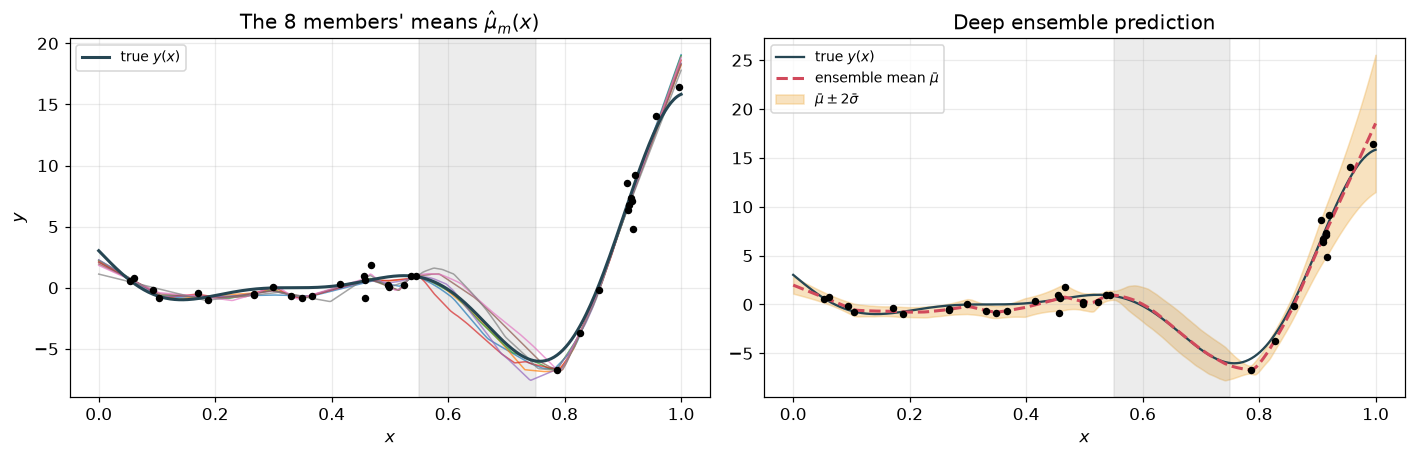

In [5]:
class Ensemble(nn.Module):
    """M independent dual-head MLPs stored as stacked weights: one batched matmul runs all members."""

    def __init__(self, M, d_in, d_out, width=32, seed0=1000):
        super().__init__()

        def init(shape, fan_in, seed, scale=1.0):
            g = torch.Generator().manual_seed(seed)
            return torch.randn(shape, generator=g) * scale * np.sqrt(2.0 / fan_in)

        self.W1 = nn.Parameter(torch.stack([init((d_in, width), d_in, seed0 + m) for m in range(M)]))
        self.W2 = nn.Parameter(torch.stack([init((width, width), width, seed0 + 100 + m) for m in range(M)]))
        self.W3 = nn.Parameter(torch.stack([init((width, 2 * d_out), width, seed0 + 200 + m, 0.1) for m in range(M)]))
        self.b1 = nn.Parameter(torch.zeros(M, 1, width))
        self.b2 = nn.Parameter(torch.zeros(M, 1, width))
        self.b3 = nn.Parameter(torch.zeros(M, 1, 2 * d_out))
        self.d_out = d_out

    def forward(self, x):                                    # x: (n, d_in) -> (M, n, d_out) twice
        h = torch.relu(x.unsqueeze(0) @ self.W1 + self.b1)
        h = torch.relu(h @ self.W2 + self.b2)
        out = h @ self.W3 + self.b3
        return out[..., :self.d_out], out[..., self.d_out:].clamp(-12, 4)


def nll_loss(mu, logvar, y):
    return 0.5 * (logvar + (y - mu) ** 2 / logvar.exp()).mean()


class DeepEnsembleModel:
    """Fit on raw (X, Y); predict returns mixture mean, aleatoric and epistemic variance in raw units."""

    def __init__(self, M=5, width=32, epochs=1500, lr=5e-3, seed0=1000, loss=nll_loss):
        self.M, self.width, self.epochs, self.lr, self.seed0, self.loss = M, width, epochs, lr, seed0, loss

    def fit(self, X, Y):
        X, Y = np.atleast_2d(np.asarray(X, float).T).T, np.atleast_2d(np.asarray(Y, float).T).T
        self.xm, self.xs = X.mean(0), X.std(0) + 1e-12
        self.ym, self.ys = Y.mean(0), Y.std(0) + 1e-12
        Xt = torch.tensor((X - self.xm) / self.xs, dtype=torch.float32)
        Yt = torch.tensor((Y - self.ym) / self.ys, dtype=torch.float32)
        self.net = Ensemble(self.M, X.shape[1], Y.shape[1], self.width, self.seed0)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        for _ in range(self.epochs):
            opt.zero_grad()
            mu, logvar = self.net(Xt)
            self.loss(mu, logvar, Yt).backward()
            opt.step()
        return self

    def members(self, X):
        X = np.atleast_2d(np.asarray(X, float).T).T
        with torch.no_grad():
            mu, logvar = self.net(torch.tensor((X - self.xm) / self.xs, dtype=torch.float32))
        return mu.numpy() * self.ys + self.ym, logvar.exp().numpy() * self.ys ** 2      # (M, n, d_out)

    def predict(self, X):
        mu, var = self.members(X)
        mu_bar = mu.mean(0)
        aleatoric = var.mean(0)
        epistemic = np.maximum((mu ** 2).mean(0) - mu_bar ** 2, 0.0)
        return mu_bar, aleatoric, epistemic


ens = DeepEnsembleModel(M=8).fit(X_train, y_train)
mu_m, var_m = ens.members(x_plot)
mu_e, al_e, ep_e = (a.ravel() for a in ens.predict(x_plot))
sd_e = np.sqrt(al_e + ep_e)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for m in range(ens.M):
    axes[0].plot(x_plot, mu_m[m, :, 0], lw=1, alpha=0.7)
axes[0].plot(x_plot, y_true(x_plot), color=COLORS["true"], lw=2, label="true $y(x)$")
axes[0].scatter(X_train, y_train, color=COLORS["data"], s=15, zorder=5)
axes[0].axvspan(*GAP, color="gray", alpha=0.15)
axes[0].set(xlabel="$x$", ylabel="$y$", title=r"The 8 members' means $\hat\mu_m(x)$")
axes[0].legend(fontsize=9)
axes[1].plot(x_plot, y_true(x_plot), color=COLORS["true"], lw=1.5, label="true $y(x)$")
axes[1].plot(x_plot, mu_e, color=COLORS["mean"], lw=2, ls="--", label=r"ensemble mean $\bar\mu$")
axes[1].fill_between(x_plot, mu_e - 2 * sd_e, mu_e + 2 * sd_e, color=COLORS["band"], alpha=0.35,
                     label=r"$\bar\mu \pm 2\bar\sigma$")
axes[1].scatter(X_train, y_train, color=COLORS["data"], s=15, zorder=5)
axes[1].axvspan(*GAP, color="gray", alpha=0.15)
axes[1].set(xlabel="$x$", title="Deep ensemble prediction")
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

The members agree near the data and **disagree** in the gap: that spread is the epistemic uncertainty.

---
## 4. Aleatoric vs. epistemic

> **Checkpoint 2.** In the gap, which component should be large? And near $x = 1$, where the data is
> noisy but present? *Answer:* epistemic in the gap (the members never saw data there); aleatoric near
> $x = 1$ (each member learned that the data scatters a lot there).

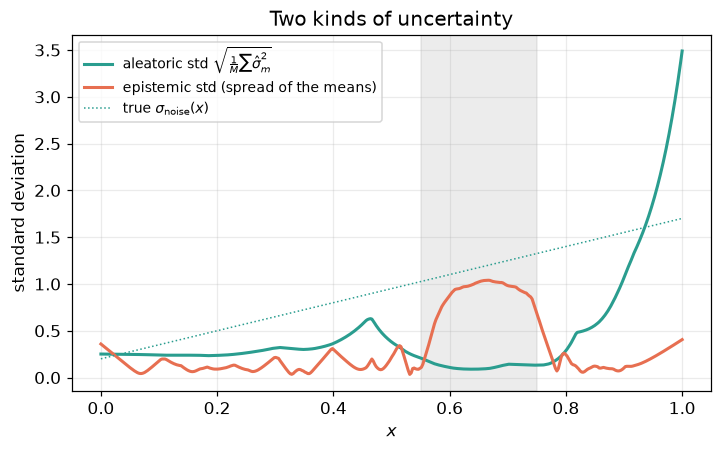

,aleatoric std,epistemic std,true noise std
"data-rich [0.1, 0.5]",0.3279,0.1278,0.6492
"gap [0.55, 0.75]",0.1223,0.8575,1.176


In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(x_plot, np.sqrt(al_e), color=COLORS["aleatoric"], lw=2, label=r"aleatoric std $\sqrt{\frac{1}{M}\sum\hat\sigma_m^2}$")
ax.plot(x_plot, np.sqrt(ep_e), color=COLORS["epistemic"], lw=2, label="epistemic std (spread of the means)")
ax.plot(x_plot, noise_std(x_plot), color=COLORS["aleatoric"], lw=1, ls=":", label=r"true $\sigma_{\mathrm{noise}}(x)$")
ax.axvspan(*GAP, color="gray", alpha=0.15)
ax.set(xlabel="$x$", ylabel="standard deviation", title="Two kinds of uncertainty")
ax.legend(fontsize=9); plt.show()

dense = (x_plot > 0.1) & (x_plot < 0.5)
pd.DataFrame({"aleatoric std": [np.sqrt(al_e[dense]).mean(), np.sqrt(al_e[in_gap]).mean()],
              "epistemic std": [np.sqrt(ep_e[dense]).mean(), np.sqrt(ep_e[in_gap]).mean()],
              "true noise std": [noise_std(x_plot[dense]).mean(), noise_std(x_plot[in_gap]).mean()]},
             index=["data-rich [0.1, 0.5]", "gap [0.55, 0.75]"])

The aleatoric curve follows the **shape** of the true noise (it grows with $x$), something the
homoscedastic GP of Section 2 could not do. The epistemic curve is small wherever data is dense and
peaks in the gap.

### More data shrinks only the epistemic part

We now run 25 extra "MDA runs" inside the gap, retrain, and compare.

In [7]:
X_more = np.sort(np.concatenate([X_train, rng.uniform(*GAP, 25)]))
y_more = np.concatenate([y_train, np.zeros(0)])
y_more = observe(X_more, np.random.default_rng(7))
ens_more = DeepEnsembleModel(M=8).fit(X_more, y_more)
_, al_2, ep_2 = (a.ravel() for a in ens_more.predict(x_plot))

pd.DataFrame({"before": [np.sqrt(al_e[in_gap]).mean(), np.sqrt(ep_e[in_gap]).mean()],
              "after 25 runs in the gap": [np.sqrt(al_2[in_gap]).mean(), np.sqrt(ep_2[in_gap]).mean()],
              "true noise": [noise_std(x_plot[in_gap]).mean(), 0.0]},
             index=["aleatoric std in gap", "epistemic std in gap"])

,before,after 25 runs in the gap,true noise
aleatoric std in gap,0.1223,0.791,1.176
epistemic std in gap,0.8575,0.171,0


The epistemic part collapses once the gap is sampled; the aleatoric part stays at the level of the true
noise. No amount of extra data removes the noise of the simulator itself, which is why, in the trust
rule of the lecture, a model can be **confident** (low epistemic) and still predict a **spread**
(aleatoric).

---
## 5. Why the $\log\hat\sigma^2$ term?

Quick-check question from the slides: what happens if we drop $\log\hat\sigma^2_m$ and train on
$\frac{1}{2}(y - \hat\mu)^2/\hat\sigma^2$ only?

In [8]:
def loss_without_log(mu, logvar, y):
    return 0.5 * ((y - mu) ** 2 / logvar.exp()).mean()


ens_bad = DeepEnsembleModel(M=8, loss=loss_without_log).fit(X_train, y_train)
_, al_bad, _ = (a.ravel() for a in ens_bad.predict(x_plot))
print(f"mean aleatoric std, full NLL:        {np.sqrt(al_e).mean():8.2f}")
print(f"mean aleatoric std, no log term:     {np.sqrt(al_bad).mean():8.2f}   "
      f"(clamp limit on the log-variance: exp(4) -> std {np.exp(2) * ens_bad.ys[0]:.1f})")

mean aleatoric std, full NLL:            0.47
mean aleatoric std, no log term:        34.96   (clamp limit on the log-variance: exp(4) -> std 35.0)


Without the log term, the loss is minimized by declaring **infinite** uncertainty everywhere: the
variance runs into the clamp we put on the log-variance head. The $\log\hat\sigma^2$ term is the price
of claiming uncertainty; the squared-error term is the price of claiming confidence. The NLL balances
the two, and its minimizer is the true variance.

---
## 6. Can we trust the predicted uncertainty? Calibration

A predictive distribution is **calibrated** if a central $p$-interval contains a fraction $p$ of new
observations. We draw 2000 fresh noisy observations at random $x$ (inside and outside the gap) and count
how many fall inside $\hat\mu \pm z\,\hat\sigma$ for several $z$.

> **Checkpoint 3.** If the coverage of the nominal 95% interval is 70%, is the model over- or
> under-confident? *Answer:* over-confident: its $\hat\sigma$ is too small. A trust rule built on it
> would skip simulations it should have run.

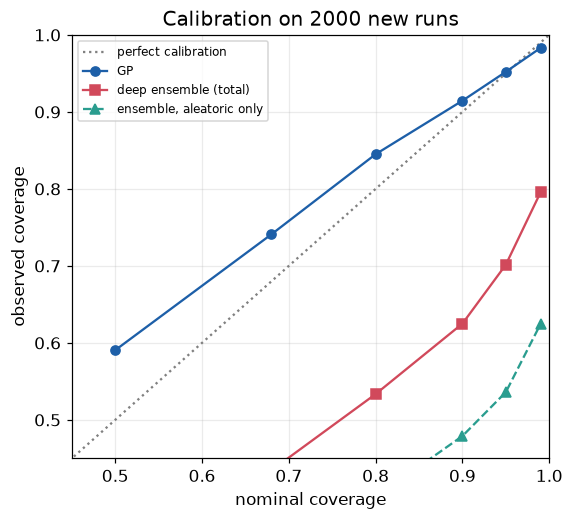

,GP,ensemble,aleatoric only
nominal,,,
0.5,0.5905,0.303,0.2255
0.68,0.741,0.4345,0.3235
0.8,0.845,0.5335,0.3995
0.9,0.9145,0.625,0.479
0.95,0.952,0.7015,0.536
0.99,0.983,0.7955,0.6245


In [9]:
X_test = rng.uniform(0, 1, 2000)
y_test = observe(X_test, rng)
mu_t_gp, sd_t_gp = gp.predict(X_test[:, None], return_std=True)
mu_t_e, al_t, ep_t = (a.ravel() for a in ens.predict(X_test))
sd_t_e = np.sqrt(al_t + ep_t)

levels = np.array([0.5, 0.68, 0.8, 0.9, 0.95, 0.99])
z = stats.norm.ppf(0.5 + levels / 2)
cov_gp = [np.mean(np.abs(y_test - mu_t_gp) <= zi * sd_t_gp) for zi in z]
cov_e = [np.mean(np.abs(y_test - mu_t_e) <= zi * sd_t_e) for zi in z]
cov_al = [np.mean(np.abs(y_test - mu_t_e) <= zi * np.sqrt(al_t)) for zi in z]

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color="gray", ls=":", label="perfect calibration")
ax.plot(levels, cov_gp, "o-", color=COLORS["gp"], label="GP")
ax.plot(levels, cov_e, "s-", color=COLORS["mean"], label="deep ensemble (total)")
ax.plot(levels, cov_al, "^--", color=COLORS["aleatoric"], label="ensemble, aleatoric only")
ax.set(xlabel="nominal coverage", ylabel="observed coverage", title="Calibration on 2000 new runs",
       xlim=(0.45, 1.0), ylim=(0.45, 1.0))
ax.legend(fontsize=8); plt.show()
pd.DataFrame({"nominal": levels, "GP": cov_gp, "ensemble": cov_e, "aleatoric only": cov_al}).set_index("nominal")

What to notice:

- Both models are roughly calibrated overall, but the curves are averages over all $x$. Look back at the
  plots: the GP band is too wide at low $x$ and too narrow at high $x$; the errors cancel in the average.
- Using the **aleatoric part only** (forgetting the members' disagreement) gives intervals that are too
  narrow, because it ignores the gap: the model would be over-confident exactly where it is guessing.
- Calibration is checked on **data the model has not seen**. In the optimization loops of the next
  notebooks we do the same check after the fact: every skipped simulation is logged with its predicted
  probabilities, and we compare them with the true outcomes.

---
## Exercises

1. **Ensemble size.** Repeat Section 4 with $M = 2, 4, 16$. How does the epistemic estimate in the gap
   change? What is the smallest $M$ you would trust?
2. **Extrapolation.** Extend `x_plot` to $[0, 1.3]$. Which model's uncertainty grows faster outside the
   data range? Is either of them large enough to cover the true function there?
3. **Bootstrap.** Train each member on a bootstrap resample of the data instead of the full set (bagging).
   Does the epistemic part change? Does calibration improve?
4. **Homoscedastic noise.** Set $\sigma_{\text{noise}}(x) = 1$. Does the GP calibration curve improve? Does the
   ensemble still learn a flat aleatoric curve?

---
## Takeaways

1. An uncertainty-aware model returns $\hat\mu(\mathbf{x})$ **and** $\hat\sigma(\mathbf{x})$. The GP gives it with
   the fit; a deep ensemble gives it from per-member variance heads plus the members' disagreement.
2. **Aleatoric** variance measures the noise of the simulator and does not shrink with data. **Epistemic**
   variance measures lack of data and shrinks where new runs land.
3. The heteroscedastic NLL needs its $\log\hat\sigma^2$ term; without it, the model claims infinite
   uncertainty.
4. A predicted $\hat\sigma$ is only useful if it is **calibrated**. Check it on unseen data before letting
   the model decide which simulations to skip.